# Gaussian Process Regression on a Light Curve

In [2]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
np.random.seed(42)

## generate light curve "data"

We generate the truth *from a GP*, so we know the right answer and can check whether the inference recovers it. The kernel is the squared exponential (RBF):

$$k(t, t') = \sigma_f^2 \exp\!\left[-\frac{(t-t')^2}{2\ell^2}\right]$$

with $\ell = 8$ days, $\sigma_f = 0.30$ mag, and per-epoch noise $\sigma_n = 0.05$ mag.

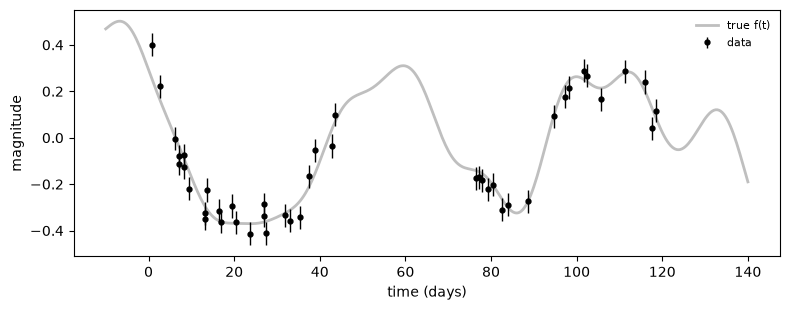

In [4]:
ELL_T, SF_T, SN_T = 8.0, 0.30, 0.05        # days, mag, mag  -- the truth


def k_rbf(x, xp, ell, sf):
    return sf ** 2 * np.exp(-0.5 * ((x[:, None] - xp[None, :]) / ell) ** 2)


# light curve with irregular cadence
t = np.concatenate([np.sort(np.random.uniform(0, 45, 26)),
                    np.sort(np.random.uniform(75, 120, 18))])
n = len(t)
tgrid = np.linspace(-10, 140, 400)

# draw truth and data jointly from N(0, K) with a cholesky trick
t_all = np.concatenate([t, tgrid])
L_all = np.linalg.cholesky(k_rbf(t_all, t_all, ELL_T, SF_T) + 1e-9 * np.eye(len(t_all)))
f_all = L_all @ np.random.normal(size=len(t_all))

f_at_t, f_true = f_all[:n], f_all[n:]
y = f_at_t + SN_T * np.random.normal(size=n) # add "observed noise"

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(tgrid, f_true, color='0.75', lw=2, label='true f(t)')
ax.errorbar(t, y, yerr=SN_T, fmt='k.', ms=7, lw=1, label='data')
ax.set_xlabel('time (days)')
ax.set_ylabel('magnitude')
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

## GP regression
With GP we assume that observed and unobserved function values are **jointly Gaussian**. Write the joint for the training values $\mathbf{y}$ and the values
$\mathbf{f}_* = \mathbf{f}(x_*)$ at any set of test times:

$$\begin{pmatrix}\mathbf{y}\\ \mathbf{f}_*\end{pmatrix} \sim \mathcal{N}\left(
\mathbf{0},\;\begin{pmatrix} K + \sigma_n^2 I & K_* \\ K_*^{\!\top} & K_{**}\end{pmatrix}\right)$$

and condition using the Gaussian conditioning identity:

$$\boxed{\;\bar{\mathbf{f}}_* = K_*^{\!\top}\big(K + \sigma_n^2 I\big)^{-1}\mathbf{y},
\qquad
\mathrm{Cov}[\mathbf{f}_*] = K_{**} - K_*^{\!\top}\big(K + \sigma_n^2 I\big)^{-1}K_*\;}$$

In [5]:
def gp_predict(t, y, ts, ell, sf, sn):
    ''' Posterior mean and variance of f at times ts given input observation (t, y). 
    
    Returns (mean, sd).
    '''
    K = k_rbf(t, t, ell, sf) + sn ** 2 * np.eye(len(t)) # K+sn^2I

    # cholesky decomposition to invert K+sn^2I
    L = np.linalg.cholesky(K) 
    alpha = np.linalg.solve(L.T, np.linalg.solve(L, y))     # (K + sn^2 I)^-1 y
    
    Ks = k_rbf(t, ts, ell, sf)
    mean = Ks.T @ alpha
    v = np.linalg.solve(L, Ks)
    var = sf ** 2 - np.sum(v ** 2, axis=0)                  # diag(Kss) = sf^2 for the RBF
    return mean, np.sqrt(np.maximum(var, 0.0))


mu, sd = gp_predict(t, y, tgrid, ELL_T, SF_T, SN_T)

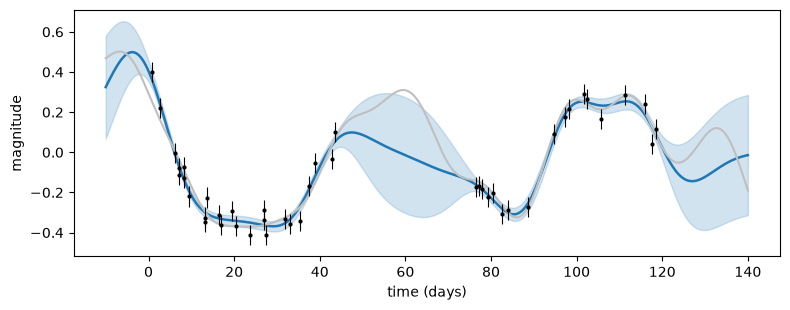

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.fill_between(tgrid, mu - sd, mu + sd, color='C0', alpha=0.2)
ax.plot(tgrid, mu, 'C0', lw=1.8)
ax.plot(tgrid, f_true, color='0.75', lw=1.5)
ax.errorbar(t, y, yerr=SN_T, fmt='k.', ms=4, lw=0.8)
ax.set_xlabel('time (days)')
ax.set_ylabel('magnitude')
plt.tight_layout()
plt.show()

## varying the kernel
$\ell$ and $\sigma_f$ determine the kernal. Try varying $\ell$ between 0.5 to 60 days. Compare the GP predictions to the observed and true light curves.

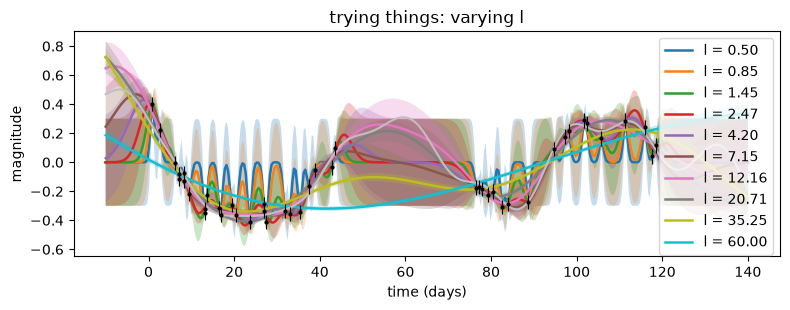

In [7]:
ltest = np.logspace(np.log10(0.5),np.log10(60),10)
mues, sads = [],[]
for i in range(len(ltest)):
    mud, sud = gp_predict(t,y,tgrid,ltest[i],SF_T,SN_T)
    mues, sads = mues + [mud], sads + [sud]


fig, ax = plt.subplots(figsize=(8, 3.2))

for i in range(len(ltest)):
    ax.plot(tgrid, mues[i], lw=1.8,label=f'l = {ltest[i]:.2f}')
    ax.fill_between(tgrid, mues[i] - sads[i], mues[i] + sads[i], alpha=0.25)
ax.plot(tgrid, f_true, color='0.75', lw=1.5)
ax.errorbar(t, y, yerr=SN_T, fmt='k.', ms=4, lw=0.8)
ax.legend(loc='upper right')
ax.set_xlabel('time (days)')
ax.set_ylabel('magnitude')
ax.set_title('trying things: varying l')
plt.tight_layout()
plt.show()

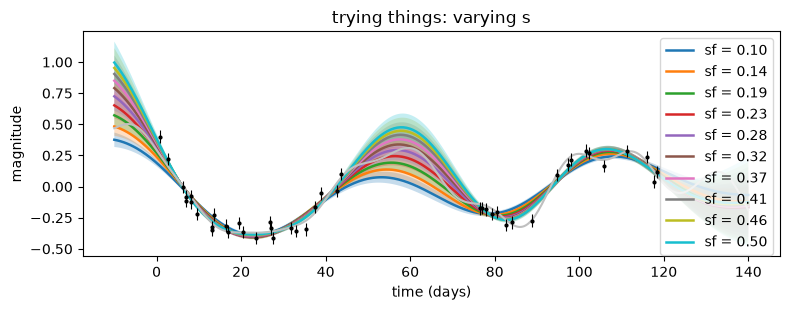

In [8]:
stest = np.linspace(0.1,0.5,10)
mues, sads = [],[]
lbest = 18.5
for i in range(len(stest)):
    mud, sud = gp_predict(t,y,tgrid,lbest,stest[i],SN_T)
    mues, sads = mues + [mud], sads + [sud]


fig, ax = plt.subplots(figsize=(8, 3.2))

for i in range(len(ltest)):
    ax.plot(tgrid, mues[i], lw=1.8,label=f'sf = {stest[i]:.2f}')
    ax.fill_between(tgrid, mues[i] - sads[i], mues[i] + sads[i], alpha=0.25)
ax.plot(tgrid, f_true, color='0.75', lw=1.5)
ax.errorbar(t, y, yerr=SN_T, fmt='k.', ms=4, lw=0.8)
ax.legend(loc='upper right')
ax.set_xlabel('time (days)')
ax.set_ylabel('magnitude')
ax.set_title('trying things: varying s')
plt.tight_layout()
plt.show()

## 4. The marginal likelihood
We can integrate out $f$ and write the marginal likelihood as: 
$$p(\mathbf{y}\mid \boldsymbol{\theta}) = \int p(\mathbf{y}\mid \mathbf{f})\,
p(\mathbf{f}\mid\boldsymbol{\theta})\, d\mathbf{f}
= \mathcal{N}(\mathbf{y};\, \mathbf{0},\, K_y), \qquad K_y = K + \sigma_n^2 I$$

$$\log p(\mathbf{y}\mid\boldsymbol{\theta}) =
\underbrace{-\tfrac{1}{2}\mathbf{y}^{\!\top}K_y^{-1}\mathbf{y}}_{\text{data fit}}
\;\underbrace{-\;\tfrac{1}{2}\log|K_y|}_{\text{complexity}}
\;-\;\tfrac{n}{2}\log 2\pi$$

where $\theta = (\ell, \sigma_f)$

In [28]:
def log_marg_likelihood(t, y, ell, sf):
    ''' log marginal likelihood
    
    Returns (full log marginal likelihood, data-fit term, complexity term).
    ''' 
    K = k_rbf(t, t, ell, sf) + SN_T ** 2 * np.eye(len(t))
    L = np.linalg.cholesky(K)
    alpha = np.linalg.solve(L.T, np.linalg.solve(L, y))
    
    fit = -0.5 * y @ alpha
    complexity = -np.sum(np.log(np.diag(L)))       # = -0.5 log|K_y|
    
    return fit + complexity - 0.5 * len(t) * np.log(2 * np.pi), fit, complexity


def lmarg_like(theta,t,y):
    ell, sf =theta
    return(log_marg_likelihood(t,y,ell,sf)[0])

def neg_log_marg(theta,t,y):
    return -1*lmarg_like(theta,t,y)
    

explore the log marginal likelihood for a range of $\ell$ and $\sigma_f$

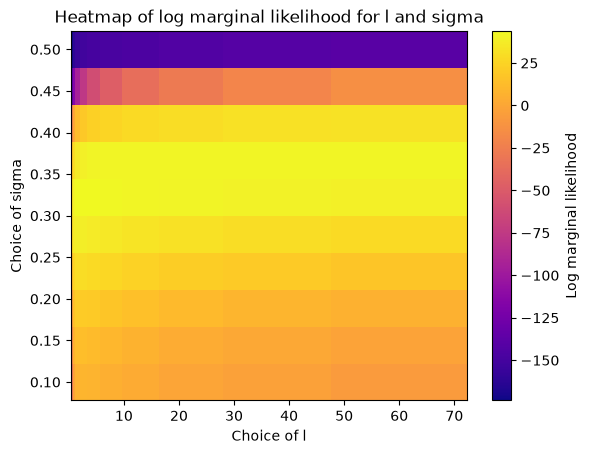

In [25]:

pairs = np.array(np.meshgrid(ltest, stest)).T.reshape(-1, 2)
xl, ys = np.array(np.meshgrid(ltest, stest))
lg = []
for i in range(len(pairs)):
    lg = lg + [log_marg_likelihood(t,y,pairs[i,0],pairs[i,1])[0]]
lg = np.array(lg)
lgz = lg.reshape(len(ltest),len(stest))
plt.pcolormesh(xl,ys,lgz, shading='auto',cmap='plasma')
plt.colorbar(label='Log marginal likelihood')
plt.xlabel('Choice of l')
plt.ylabel('Choice of sigma')
plt.title('Heatmap of log marginal likelihood for l and sigma')
plt.show()


emcee HAMMER it! Implement a reasonable prior and sample the posterior on $\ell, \sigma_f$. Plot the posterior and compare it to the truth

In [68]:
theta_guess = [12,0.35]
import scipy.optimize as opt
import corner
theta_est = opt.minimize(neg_log_marg,theta_guess,method='Nelder-Mead',args=(t,y)).x
print(theta_est)

def log_prior(theta):
    ell, sf = theta
    if not (0.1 < ell < 100): return -np.inf
    if not (0.1 < sf < 0.5 ): return -np.inf
    return 0.0

def log_post(theta, t,s):
    lp = log_prior(theta)
    if not np.isfinite(lp): return -np.inf
    return lp + lmarg_like(theta, t,s)


[7.55189159 0.23054722]


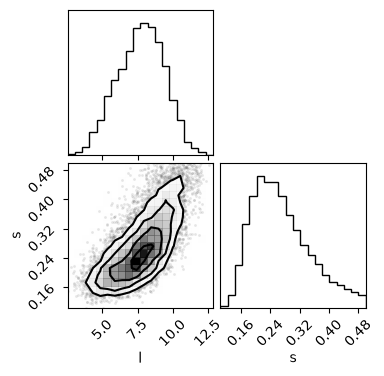

In [69]:

import emcee
ndim, nwalkers, nsteps, nburn = [2,32,5000,600]
pos = theta_guess + 1e-1*np.random.rand(nwalkers,ndim)

sampler = emcee.EnsembleSampler(nwalkers, ndim, 
                                log_post, 
                                args=(t,y,))

_ = sampler.run_mcmc(pos, nsteps, progress=False)
flat = sampler.get_chain(discard=nburn,thin=15, flat=True)
labels =['l','s']
fig = plt.figure(figsize=(4,4))
fig = corner.corner(flat, labels=labels, fig=fig)
plt.show()


Plot the magnitude-time predictions from the GP using the MAP of your posterior alongside observed data.

In [73]:
flat_log_prob = sampler.get_log_prob(discard=nburn,thin=15,flat=True)
b_index = np.argmax(flat_log_prob)
mlvs = flat[b_index]
lp, sp = mlvs
print('Most likely l and s:',f'{mlvs[0]:.3f},',f'{mlvs[1]:.3f}')
print('True l and s:',ELL_T,',',SF_T)


Most likely l and s: 7.560, 0.231
True l and s: 8.0 , 0.3


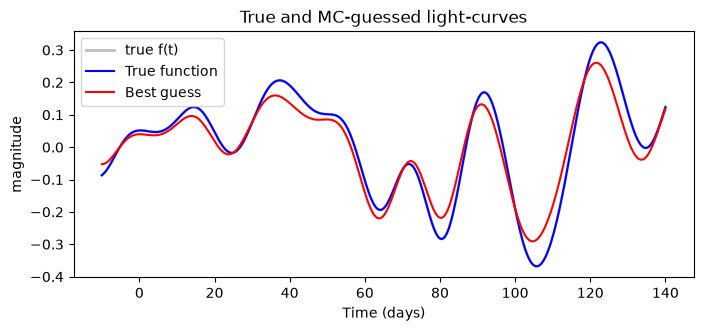

In [77]:
def k_rbf(x, xp, ell, sf):
    return sf ** 2 * np.exp(-0.5 * ((x[:, None] - xp[None, :]) / ell) ** 2)

# light curve with irregular cadence
t = np.concatenate([np.sort(np.random.uniform(0, 45, 26)),
                    np.sort(np.random.uniform(75, 120, 18))])
n = len(t)
tgrid = np.linspace(-10, 140, 400)

# draw truth and data jointly from N(0, K) with a cholesky trick
t_all = np.concatenate([t, tgrid])
L_all = np.linalg.cholesky(k_rbf(t_all, t_all, ELL_T, SF_T) + 1e-9 * np.eye(len(t_all)))
lguess = np.linalg.cholesky(k_rbf(t_all, t_all, lp, sp) + 1e-9 * np.eye(len(t_all)))
randmat = np.random.normal(size=len(t_all))
f_all = L_all @ randmat
g_all = lguess @ randmat

f_at_t, f_true = f_all[:n], f_all[n:]
g_true = g_all[n:]

y = f_at_t + SN_T * np.random.normal(size=n) # add "observed noise"

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(tgrid, f_true, color='0.75', lw=2, label='true f(t)')


ftrue = k_rbb(tgrid, ELL_T, SF_T)
fguess = k_rbb(tgrid, mlvs[0], mlvs[1])

plt.plot(tgrid,f_true, color='blue',label='True function')
plt.plot(tgrid,g_true, color='red',label='Best guess')
plt.xlabel('Time (days)')
plt.ylabel('magnitude')
plt.title('True and MC-guessed light-curves')
plt.legend()
plt.show()